> **This is a template demo with made-up data.** It exists to show how each kind of notebook cell looks on the site. None of the numbers mean anything.

## The question

Does the amount of time a student studies relate to their quiz score? It's a toy question, chosen because it produces every kind of output a real project page needs: a single number, a table, a few charts and some printed text.

## Setting up

I generate 200 fake students with a fixed random seed so the page looks the same every time it's built. I made the relationship deliberately noisy, because real data rarely looks like a clean line.

In [1]:
import numpy as np
import pandas as pd
import altair as alt

rng = np.random.default_rng(42)
n = 200
hours = rng.gamma(shape=2.0, scale=2.0, size=n).round(1)
group = rng.choice(["Morning", "Afternoon", "Evening"], size=n, p=[0.3, 0.45, 0.25])
score = (55 + 4.2 * hours + rng.normal(0, 9, size=n)).clip(0, 100).round(0)

df = pd.DataFrame({"hours": hours, "study_time": group, "score": score})
df.head()

,hours,study_time,score
0,4.2,Morning,89.0
1,5.7,Morning,64.0
2,3.7,Evening,59.0
3,3.3,Morning,65.0
4,6.2,Evening,76.0


## A first number

Before any modelling, I check the correlation. **Why Pearson's $r$?** Both variables are continuous and the scatter plot below looks roughly linear, so $r$ is a reasonable summary. If the plot had curved, I would have used Spearman's rank correlation instead.

In [2]:
#| label: Pearson's r (hours vs. score)
round(df["hours"].corr(df["score"]), 3)

np.float64(0.746)

## Looking at the relationship

A scatter plot comes before a regression line, because a single coefficient can hide outliers or curvature. Hover over any point to see its values.

In [3]:
#| caption: Each dot is one fake student. The relationship is positive but noisy.
alt.Chart(df).mark_circle(opacity=0.8).encode(
    x=alt.X("hours:Q", title="Hours studied"),
    y=alt.Y("score:Q", title="Quiz score", scale=alt.Scale(domain=[30, 100])),
    tooltip=["hours", "score", "study_time"],
).properties(title="Score rises with study time", height=320)

alt.Chart(...)

## Comparing groups

Next I check whether the time of day changes anything. I chose **a bar chart of means** over box plots here because the audience for this page is general. In a real write-up I'd include the spread as well.

In [4]:
#| collapse
summary = (
    df.groupby("study_time", as_index=False)
      .agg(students=("score", "size"), mean_score=("score", "mean"), mean_hours=("hours", "mean"))
      .round(1)
      .sort_values("mean_score", ascending=False)
)
summary

,study_time,students,mean_score,mean_hours
1,Evening,49,72.2,4.8
2,Morning,57,72.2,4.1
0,Afternoon,94,70.7,3.9


In [5]:
#| hide
#| caption: Average score by time of day (made-up data).
alt.Chart(summary).mark_bar(size=36).encode(
    x=alt.X("mean_score:Q", title="Mean quiz score", scale=alt.Scale(domain=[0, 100])),
    y=alt.Y("study_time:N", title=None, sort="-x"),
    tooltip=["study_time", "students", "mean_score"],
).properties(title="Mean score by time of day", height=170)

alt.Chart(...)

## Fitting a line

A simple least-squares fit: $\hat{y} = \beta_0 + \beta_1 x$. I print the coefficients rather than showing a full model summary, because only the slope matters for the question.

In [6]:
slope, intercept = np.polyfit(df["hours"], df["score"], deg=1)
residuals = df["score"] - (intercept + slope * df["hours"])

print(f"intercept : {intercept:6.2f}")
print(f"slope     : {slope:6.2f} points per hour")
print(f"resid. SD : {residuals.std():6.2f}")

intercept :  56.55
slope     :   3.60 points per hour
resid. SD :   9.34


## A static chart, too

Some charts are easier to make in matplotlib. The site's matplotlib style file gives them the same dark look, saved as images.

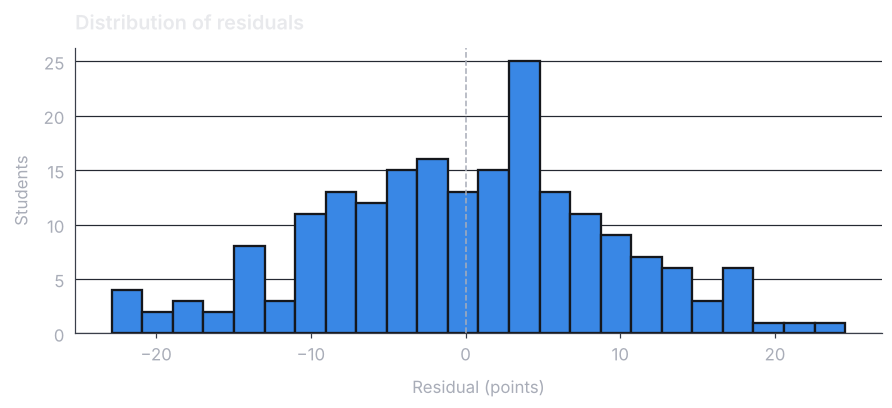

In [7]:
#| caption: Residuals look roughly symmetric around zero, a quick sanity check on the linear fit.
import matplotlib.pyplot as plt
plt.style.use("portfolio.mplstyle")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(residuals, bins=24, color="#3987e5", edgecolor="#15171c", linewidth=1.5)
ax.axvline(0, color="#a9adb8", linewidth=1, linestyle="--")
ax.set(title="Distribution of residuals", xlabel="Residual (points)", ylabel="Students")
plt.show()

## What I'd do differently

- With real data I'd check for **confounders**: students who study more may differ in other ways.
- The groups are unbalanced, so I'd report confidence intervals, not just means.

*End of the template demo.*